# Optimal, Greedy, and Uniform Sequential Discrimination

This notebook compares exhaustive optimal allocation, greedy allocation, and uniform allocation on exactly the same cases and sensor budgets. Greedy and uniform use the same lowest-pair-error tree rule, so their difference isolates the value of adaptive sensor placement. It focuses on two research questions:

1. How much final error is added by greedy and uniform allocation?
2. How much computation time does each method save?

The default pilot uses one realization from every field-family, $K$, and $M$ cell in both the 1D and 2D lite benchmarks.

In [6]:
from pathlib import Path
import sys

import matplotlib.pyplot as plt
from IPython.display import Markdown, display

working_directory = Path.cwd().resolve()
MODULE_DIRECTORY = (
    working_directory / "min-error-sequential"
    if (working_directory / "min-error-sequential").is_dir()
    else working_directory
)
if str(MODULE_DIRECTORY) not in sys.path:
    sys.path.insert(0, str(MODULE_DIRECTORY))

from comparison_analysis import (
    make_combined_comparison_plots,
    paired_summary,
    run_paired_dataset,
)

## Run settings

The pilot is intended for checking the comparison and choosing plots. It is not large enough for final statistical conclusions. Set `RUN_ALL_REPLICATES = True` to use all 3,000 cases in each dimension. The full run takes much longer because every case also runs exhaustive search.

In [7]:
DATASETS = ["lite_benchmark_1d", "lite_benchmark_2d"]
RUN_ALL_REPLICATES = True
REPLICATES_PER_CELL = None if RUN_ALL_REPLICATES else 1
RESULTS_ROOT = MODULE_DIRECTORY / "results" / "algorithm_comparison"

print("Run mode:", "all 3,000 cases" if RUN_ALL_REPLICATES else "pilot: 1 replicate per cell")
print("Results directory:", RESULTS_ROOT)

Run mode: all 3,000 cases
Results directory: /Users/avishka/Academic/PhD/Research/QSN Research/Repos/quantum-sensor-placement-research/min-error-sequential/results/algorithm_comparison


## Run all three algorithms

Each record is paired: optimal, greedy, and uniform receive the same $K$, $M$, budget, phase gaps, and sparse $P_{ijmn}$ values.

In [8]:
records_by_dataset = {}
for dataset in DATASETS:
    display(Markdown(f"### Running `{dataset}`"))
    records_by_dataset[dataset] = run_paired_dataset(
        dataset,
        replicates_per_cell=REPLICATES_PER_CELL,
        results_root=RESULTS_ROOT,
    )

### Running `lite_benchmark_1d`

lite_benchmark_1d: completed case 1/3000 (gaussian, K=3, M=3)
lite_benchmark_1d: completed case 2/3000 (gaussian, K=3, M=3)
lite_benchmark_1d: completed case 3/3000 (gaussian, K=3, M=3)
lite_benchmark_1d: completed case 4/3000 (gaussian, K=3, M=3)
lite_benchmark_1d: completed case 5/3000 (gaussian, K=3, M=3)
lite_benchmark_1d: completed case 6/3000 (gaussian, K=3, M=3)
lite_benchmark_1d: completed case 7/3000 (gaussian, K=3, M=3)
lite_benchmark_1d: completed case 8/3000 (gaussian, K=3, M=3)
lite_benchmark_1d: completed case 9/3000 (gaussian, K=3, M=3)
lite_benchmark_1d: completed case 10/3000 (gaussian, K=3, M=3)
lite_benchmark_1d: completed case 11/3000 (gaussian, K=3, M=3)
lite_benchmark_1d: completed case 12/3000 (gaussian, K=3, M=3)
lite_benchmark_1d: completed case 13/3000 (gaussian, K=3, M=3)
lite_benchmark_1d: completed case 14/3000 (gaussian, K=3, M=3)
lite_benchmark_1d: completed case 15/3000 (gaussian, K=3, M=3)
lite_benchmark_1d: completed case 16/3000 (gaussian, K=3, M=3)
l

KeyboardInterrupt: 

## Paired comparison summary

In [ ]:
summary_lines = [
    "| Dataset | Method | Cases | Paired runs | Mean error gap | Maximum gap | Exact-error matches | Median speedup |",
    "|---|---|---:|---:|---:|---:|---:|---:|",
]
for dataset, records in records_by_dataset.items():
    summary = paired_summary(records)
    for method, prefix in (("Greedy", "greedy"), ("Uniform", "uniform")):
        summary_lines.append(
            f"| {dataset} | {method} | {summary['cases']} | {summary['runs']} | "
            f"{summary[f'{prefix}_mean_gap']:.4f} | "
            f"{summary[f'{prefix}_maximum_gap']:.4f} | "
            f"{100 * summary[f'{prefix}_exact_match_rate']:.1f}% | "
            f"{summary[f'{prefix}_median_speedup']:.1f}x |"
        )
display(Markdown("\n".join(summary_lines)))

| Dataset | Method | Cases | Paired runs | Mean error gap | Maximum gap | Exact-error matches | Median speedup |
|---|---|---:|---:|---:|---:|---:|---:|
| lite_benchmark_1d | Greedy | 18 | 72 | 0.1043 | 0.3519 | 11.1% | 23.3x |
| lite_benchmark_1d | Uniform | 18 | 72 | 0.2488 | 0.4513 | 0.0% | 332.1x |
| lite_benchmark_2d | Greedy | 18 | 72 | 0.1360 | 0.3296 | 5.6% | 21.8x |
| lite_benchmark_2d | Uniform | 18 | 72 | 0.2490 | 0.4806 | 0.0% | 337.9x |

## Comparison plots

1. **Mean error curves:** shows the quality-budget tradeoff.
2. **Runtime speedup:** shows the computational benefit relative to exhaustive search.
3. **Error gap by field family:** compares Gaussian, sinusoidal, and quadratic fields in that order.

## Mean error curves

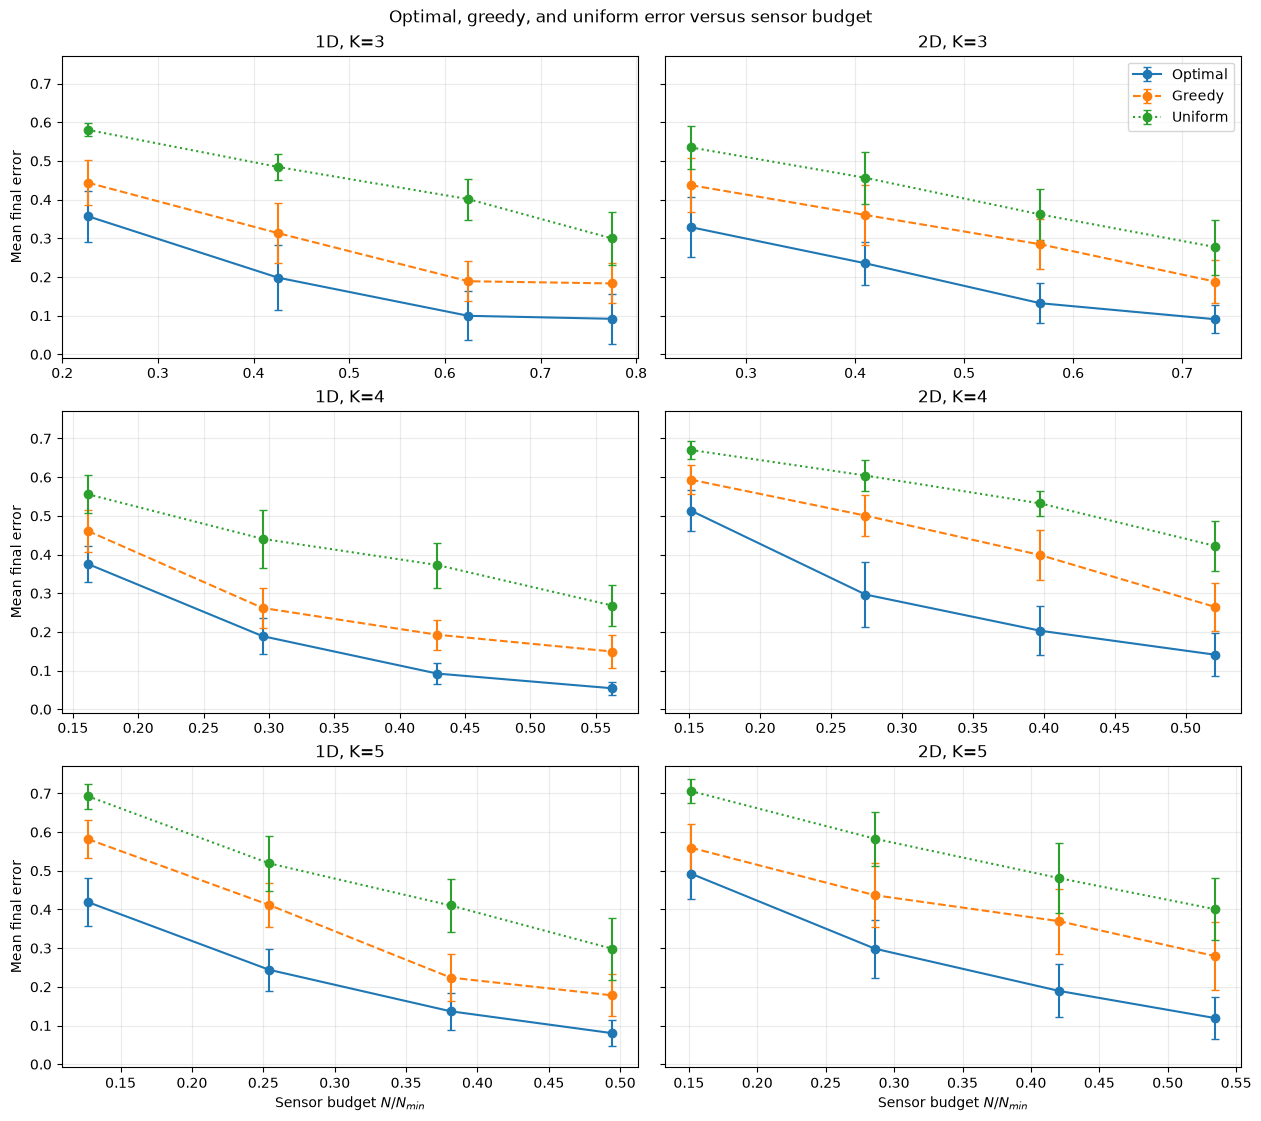

## Runtime speedup

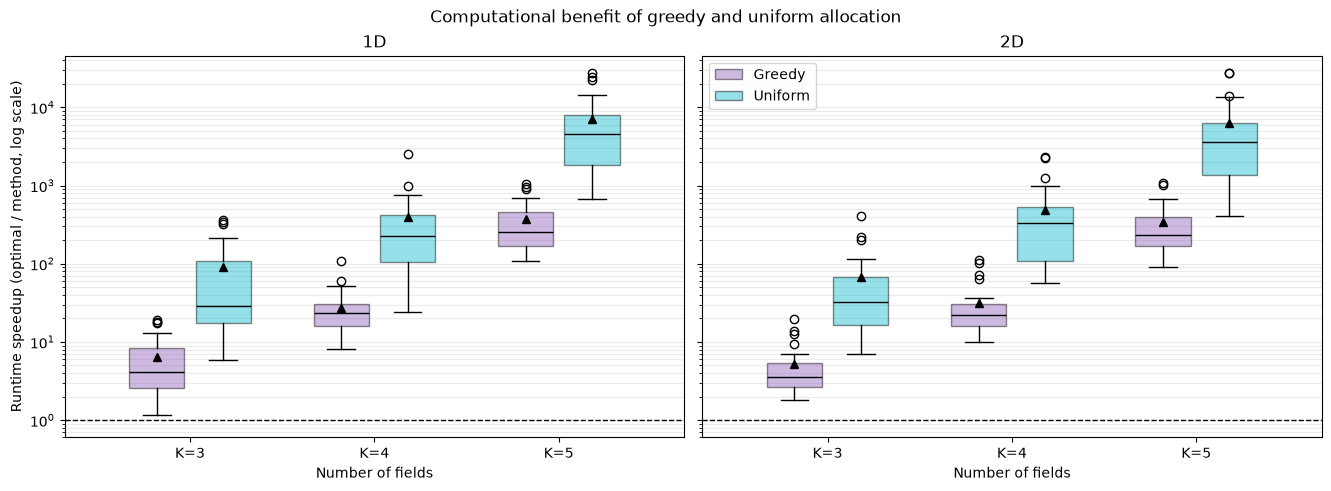

## Error gap by field family

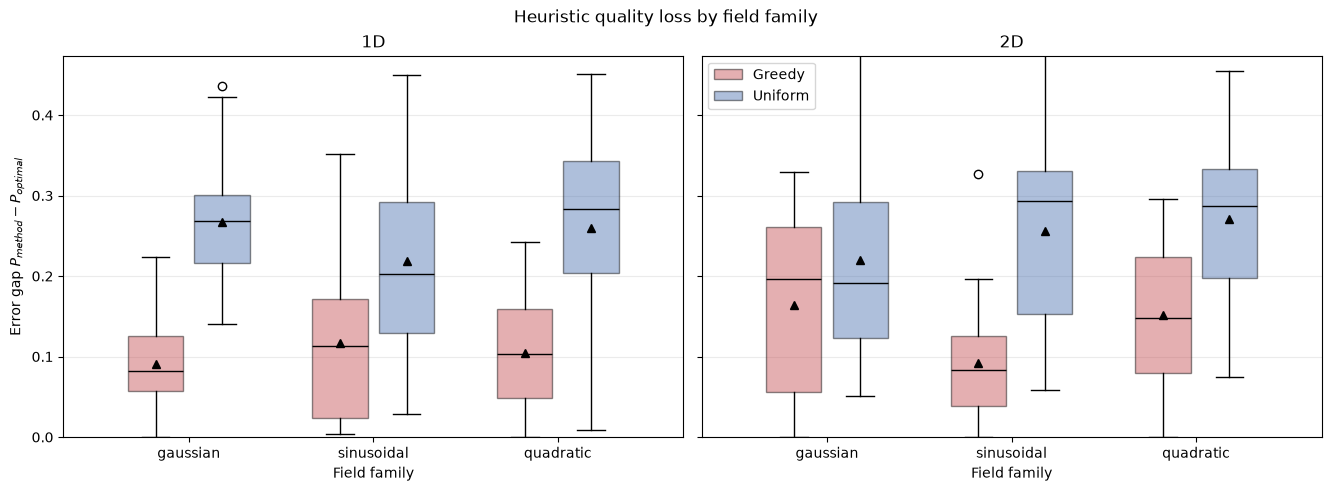

In [ ]:
for title, figure in make_combined_comparison_plots(
    records_by_dataset, results_root=RESULTS_ROOT
):
    display(Markdown(f"## {title}"))
    display(figure)
    plt.close(figure)

## Saved files

The notebook saves detailed tables separately by dimension and puts the side-by-side figures in one combined folder:

```text
results/algorithm_comparison/
├── lite_benchmark_1d/tables/
├── lite_benchmark_2d/tables/
└── combined/figures/
    ├── mean_error_curves.*
    ├── runtime_speedup.*
    └── error_gap_by_field_family.*
```

Each figure is saved as a 300-dpi PNG and a vector PDF.